# Compare `results_z` models vs scTranslator 10K on proteins only

This notebook rebuilds the `results_z` predictions, loads the saved **scTranslator 10K** predictions, restricts the comparison to the **shared proteins / shared samples**, and runs the comparison in **two parts**:

1. **Raw `results_z` values** on the shared protein set.
2. **scTranslator-style per-sample min-max normalization** applied to the `results_z` truth / predictions, while scTranslator 10K predictions are used on their saved min-max scale.

The notebook keeps the original `results_z` prediction logic (including the feature-imputation behavior and no added intercept term, just like the source notebook).

> Edit the paths in the config cell if your folder layout is different.

In [1]:
import ast
import glob
import os
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

EPS = 1e-8
DATASETS = ['iTRAQ', 'LabelFree', 'TMT']

## Configuration

Set these paths to match the layout used by your existing notebooks.

The defaults below assume this new notebook lives next to the existing notebooks. For `LabelFree`, the original benchmark notebook appears to have a likely output-dir typo, so both a normal and a fallback path are included.

In [9]:
import ast
import glob
import os
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

EPS = 1e-8
DATASETS = ['iTRAQ', 'LabelFree', 'TMT']


def first_existing_path(candidates, label, expect_dir=None, required=True):
    for candidate in candidates:
        path = Path(candidate).resolve()
        if expect_dir is True and path.is_dir():
            return path
        if expect_dir is False and path.is_file():
            return path
        if expect_dir is None and path.exists():
            return path
    if required:
        checked = "\n".join(str(Path(c).resolve()) for c in candidates)
        raise FileNotFoundError(f"Could not find {label}. Checked:\n{checked}")
    return None


def find_dir_with_markers(candidates, markers, label):
    checked = []
    for candidate in candidates:
        path = Path(candidate).resolve()
        checked.append(str(path))
        if path.is_dir() and all((path / m).exists() for m in markers):
            return path
    checked_str = "\n".join(checked)
    raise FileNotFoundError(f"Could not locate {label}. Checked:\n{checked_str}")


CWD = Path.cwd().resolve()

# robust even if the notebook is launched from project root or notebooks/
NOTEBOOK_DIR = find_dir_with_markers(
    [CWD, CWD / "notebooks", CWD.parent, CWD.parent / "notebooks"],
    markers=["itraq", "labelfree", "tmt"],
    label="notebook directory",
)

PROJECT_ROOT = find_dir_with_markers(
    [NOTEBOOK_DIR.parent, CWD, CWD.parent, NOTEBOOK_DIR],
    markers=["data", "model_results"],
    label="project root",
)

# this is where the *.joblib validation files actually are in your screenshot
VALIDATION_DATA_DIR = first_existing_path(
    [
        NOTEBOOK_DIR / "val_data",
        PROJECT_ROOT / "val_data",
        PROJECT_ROOT / "data",
        NOTEBOOK_DIR / "data",
    ],
    label="validation data directory",
    expect_dir=True,
)

# this is where *_best.csv should be searched
RESULTS_Z_RESULTS_DIR = first_existing_path(
    [
        NOTEBOOK_DIR / "results_val",
        PROJECT_ROOT / "results_val",
        PROJECT_ROOT / "model_results",
        NOTEBOOK_DIR / "model_results",
    ],
    label="results_z/model_results directory",
    expect_dir=True,
)

RAW_DATA_DIR = first_existing_path(
    [PROJECT_ROOT / "data", NOTEBOOK_DIR / "data"],
    label="raw data directory",
    expect_dir=True,
    required=False,
)

OUTPUT_DIR = (NOTEBOOK_DIR / "comparison_results_z_vs_scTranslator_10K").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def sc_10k_candidates(ds_folder: str):
    return [
        NOTEBOOK_DIR / ds_folder / "predictions_10K.npz",
        NOTEBOOK_DIR / ds_folder / "predictions10k.npz",
        NOTEBOOK_DIR / "scTranslator-validation-newdata" / ds_folder / "predictions_10K.npz",
        NOTEBOOK_DIR / "scTranslator-validation-newdata" / ds_folder / "predictions10k.npz",
        PROJECT_ROOT / "scTranslator-validation-newdata" / ds_folder / "predictions_10K.npz",
        PROJECT_ROOT / "scTranslator-validation-newdata" / ds_folder / "predictions10k.npz",
        PROJECT_ROOT / ds_folder / "predictions_10K.npz",
        PROJECT_ROOT / ds_folder / "predictions10k.npz",
    ]


SCTRANSLATOR_10K_FILES = {
    "iTRAQ": sc_10k_candidates("itraq"),
    "LabelFree": sc_10k_candidates("labelfree"),
    "TMT": sc_10k_candidates("tmt"),
}

# backward-compatible aliases for later cells
MODEL_RESULTS_DIR = RESULTS_Z_RESULTS_DIR
VAL_DATA_DIR = VALIDATION_DATA_DIR
DATA_DIR = VALIDATION_DATA_DIR

print("CWD                =", CWD)
print("NOTEBOOK_DIR       =", NOTEBOOK_DIR)
print("PROJECT_ROOT       =", PROJECT_ROOT)
print("VALIDATION_DATA_DIR=", VALIDATION_DATA_DIR)
print("RESULTS_Z_RESULTS_DIR =", RESULTS_Z_RESULTS_DIR)
print("RAW_DATA_DIR       =", RAW_DATA_DIR)
print("OUTPUT_DIR         =", OUTPUT_DIR)

CWD                = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks
NOTEBOOK_DIR       = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks
PROJECT_ROOT       = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation
VALIDATION_DATA_DIR= C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data
RESULTS_Z_RESULTS_DIR = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\results_val
RAW_DATA_DIR       = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\data
OUTPUT_DIR         = C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\comparison_results_z_vs_scTranslator_10K


In [10]:
def load_dataset_joblib(dataset_name: str, kind: str, base_dir: Path):
    candidates = [
        base_dir / f"{dataset_name}_{kind}.joblib",
        base_dir / f"{dataset_name.lower()}_{kind}.joblib",
        base_dir / f"{dataset_name.upper()}_{kind}.joblib",
    ]
    path = first_existing_path(
        candidates,
        label=f"{dataset_name} {kind} joblib",
        expect_dir=False,
    )
    obj = joblib.load(path)

    if isinstance(obj, pd.DataFrame):
        obj.index = obj.index.astype(str)
        obj.columns = obj.columns.astype(str)

    return obj, path

In [3]:
def find_existing_path(candidates, label):
    for path in candidates:
        if Path(path).exists():
            return Path(path)
    checked = "\n".join(str(p) for p in candidates)
    raise FileNotFoundError(f"Could not find {label}. Checked:\n{checked}")


def safe_pearson(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 2:
        return np.nan
    yt = np.asarray(y_true[mask], dtype=float)
    yp = np.asarray(y_pred[mask], dtype=float)
    if np.std(yt) == 0 or np.std(yp) == 0:
        return np.nan
    return pearsonr(yt, yp)[0]


def safe_spearman(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 2:
        return np.nan
    yt = np.asarray(y_true[mask], dtype=float)
    yp = np.asarray(y_pred[mask], dtype=float)
    if np.std(yt) == 0 or np.std(yp) == 0:
        return np.nan
    return spearmanr(yt, yp)[0]


def safe_cosine(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 1:
        return np.nan
    yt = np.asarray(y_true[mask], dtype=float)
    yp = np.asarray(y_pred[mask], dtype=float)
    denom = np.linalg.norm(yt) * np.linalg.norm(yp)
    if denom == 0:
        return np.nan
    return float(np.dot(yt, yp) / denom)


def safe_mse(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 1:
        return np.nan
    return mean_squared_error(y_true[mask], y_pred[mask])


def safe_mae(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 1:
        return np.nan
    return mean_absolute_error(y_true[mask], y_pred[mask])


def safe_r2(y_true, y_pred):
    mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if mask.sum() < 2:
        return np.nan
    yt = np.asarray(y_true[mask], dtype=float)
    yp = np.asarray(y_pred[mask], dtype=float)
    if np.std(yt) == 0:
        return np.nan
    return r2_score(yt, yp)


def normalization(x: pd.Series, low: float = EPS, high: float = 1.0) -> pd.Series:
    # x is one sample's vector across proteins
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax):
        return pd.Series(np.nan, index=x.index, dtype='float64')
    if xmax == xmin:
        return pd.Series(low, index=x.index, dtype='float64')
    return low + (x - xmin) / (xmax - xmin) * (high - low)


def compute_group_metrics(df_long, true_col, pred_col, group_cols):
    rows = []
    for keys, g in df_long.groupby(group_cols, observed=True, sort=False):
        yt = g[true_col].to_numpy(dtype=float)
        yp = g[pred_col].to_numpy(dtype=float)
        row = {
            'PCC': safe_pearson(yt, yp),
            'Spearman': safe_spearman(yt, yp),
            'Cosine': safe_cosine(yt, yp),
            'MSE': safe_mse(yt, yp),
            'MAE': safe_mae(yt, yp),
            'R2': safe_r2(yt, yp),
            'N': int((~np.isnan(yt) & ~np.isnan(yp)).sum()),
        }
        if isinstance(keys, tuple):
            row.update(dict(zip(group_cols, keys)))
        else:
            row[group_cols[0]] = keys
        rows.append(row)
    return pd.DataFrame(rows)


def summarize_metrics(metrics_df, by=('Dataset', 'Method')):
    metric_cols = ['PCC', 'Spearman', 'Cosine', 'MSE', 'MAE', 'R2', 'N']
    out = (
        metrics_df
        .groupby(list(by), observed=True)[metric_cols]
        .agg(['mean', 'median', 'std'])
    )
    out.columns = ['_'.join(col).strip() for col in out.columns]
    return out.reset_index()


## Load the `results_z` protein models

This reproduces the prediction logic from `4. results_z.ipynb` and keeps the same behavior for missing RNA features (impute missing features as zero by simply dropping them from the dot product).

In [4]:
best_files = glob.glob(os.path.join(RESULTS_Z_RESULTS_DIR, '*_best.csv'))
print(f'Found {len(best_files)} *_best.csv files')

if not best_files:
    raise FileNotFoundError(f'No *_best.csv files found in {RESULTS_Z_RESULTS_DIR}')

best_tables = [pd.read_csv(f) for f in best_files]
df_best_all = pd.concat(best_tables, ignore_index=True)
df_best_all = df_best_all.sort_values('protein').reset_index(drop=True)

display(df_best_all.head())
print('Combined shape:', df_best_all.shape)

Found 1809 *_best.csv files


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08


Combined shape: (1809, 10)


In [11]:
def build_results_z_dataset(dataset_name: str, df_best: pd.DataFrame, val_data_dir: Path):
    rna_df, rna_path = load_dataset_joblib(dataset_name, 'transcriptomics', val_data_dir)
    prot_df, prot_path = load_dataset_joblib(dataset_name, 'proteomics', val_data_dir)

    rna_z = rna_df.fillna(0)
    available_feats = set(rna_z.columns)

    ds_predictions = []
    ds_truth = []
    valid_proteins = []
    missing_warned = False

    for _, row in df_best.iterrows():
        protein = row['protein']
        if protein not in prot_df.columns:
            continue

        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        missing_feats = [f for f in needed_feats if f not in available_feats]

        if missing_feats and not missing_warned:
            print(f'[{dataset_name}] Missing RNA features detected; imputing them as 0 in the dot product.')
            missing_warned = True

        present_feats = [f for f in needed_feats if f in available_feats]
        if present_feats:
            weights = np.array([coeffs[f] for f in present_feats], dtype=float)
            y_pred = rna_z[present_feats].dot(weights)
        else:
            y_pred = pd.Series(0.0, index=rna_z.index)

        y_true = prot_df[protein]

        valid_proteins.append(protein)
        ds_predictions.append(y_pred.to_numpy())
        ds_truth.append(y_true.to_numpy())

    if not valid_proteins:
        raise ValueError(f'No valid proteins were reconstructed for {dataset_name}')

    pred_df = pd.DataFrame(np.vstack(ds_predictions).T, index=rna_df.index, columns=valid_proteins)
    true_df = pd.DataFrame(np.vstack(ds_truth).T, index=prot_df.index, columns=valid_proteins)

    pred_df.index = pred_df.index.astype(str)
    true_df.index = true_df.index.astype(str)
    pred_df.columns = pred_df.columns.astype(str)
    true_df.columns = true_df.columns.astype(str)

    pred_df = pred_df.loc[true_df.index, true_df.columns]

    return {
        'pred_raw': pred_df,
        'true_raw': true_df,
        'samples': pred_df.index.tolist(),
        'proteins': pred_df.columns.tolist(),
        'rna_path': rna_path,
        'prot_path': prot_path,
    }


results_z_data = {ds: build_results_z_dataset(ds, df_best_all, VAL_DATA_DIR) for ds in DATASETS}

for ds, obj in results_z_data.items():
    print(f'{ds}: {obj["pred_raw"].shape[0]} samples x {obj["pred_raw"].shape[1]} proteins')
    print(f'  RNA loaded from : {obj["rna_path"]}')
    print(f'  Prot loaded from: {obj["prot_path"]}')

[iTRAQ] Missing RNA features detected; imputing them as 0 in the dot product.
[LabelFree] Missing RNA features detected; imputing them as 0 in the dot product.
[TMT] Missing RNA features detected; imputing them as 0 in the dot product.
iTRAQ: 276 samples x 1807 proteins
  RNA loaded from : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\iTRAQ_transcriptomics.joblib
  Prot loaded from: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\iTRAQ_proteomics.joblib
LabelFree: 360 samples x 1807 proteins
  RNA loaded from : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\LabelFree_transcriptomics.joblib
  Prot loaded from: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\LabelFree_proteomics.joblib
TMT: 1924 samples x 1807 proteins
  RNA loaded from : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\TMT_transcriptomics.joblib
  Prot loaded from: C:\Users\h

## Load saved scTranslator 10K predictions

This loader uses the saved `predictions_10K.npz` files from the benchmark notebooks and aligns them back to sample / protein names.

In [12]:
def load_sctranslator_10k_dataset(dataset_name: str, truth_data_dir: Path):
    pred_path = first_existing_path(
        SCTRANSLATOR_10K_FILES[dataset_name],
        label=f"scTranslator 10K predictions for {dataset_name}",
        expect_dir=False,
    )

    npz = np.load(pred_path, allow_pickle=True)

    required_keys = {"predictions", "protein_names", "cell_names"}
    missing_keys = required_keys.difference(npz.files)
    if missing_keys:
        raise KeyError(
            f"{pred_path} is missing required arrays: {sorted(missing_keys)}. "
            f"Available arrays: {sorted(npz.files)}"
        )

    preds = npz["predictions"]
    protein_names = pd.Index(npz["protein_names"].astype(str), name="Protein")
    cell_names = pd.Index(npz["cell_names"].astype(str), name="Sample")

    pred_df = pd.DataFrame(preds, index=cell_names, columns=protein_names)
    pred_df.index = pred_df.index.astype(str)
    pred_df.columns = pred_df.columns.astype(str)

    prot_raw, prot_path = load_dataset_joblib(dataset_name, "proteomics", truth_data_dir)

    shared_samples = [s for s in pred_df.index if s in prot_raw.index]
    shared_proteins = [p for p in pred_df.columns if p in prot_raw.columns]

    if not shared_samples:
        raise ValueError(f"No overlapping samples between {pred_path} and {prot_path}")
    if not shared_proteins:
        raise ValueError(f"No overlapping proteins between {pred_path} and {prot_path}")

    pred_df = pred_df.loc[shared_samples, shared_proteins]
    true_raw = prot_raw.loc[shared_samples, shared_proteins]

    return {
        "pred_10k": pred_df,
        "true_raw": true_raw,
        "samples": pred_df.index.tolist(),
        "proteins": pred_df.columns.tolist(),
        "pred_path": pred_path,
        "prot_path": prot_path,
    }


sct10k_data = {ds: load_sctranslator_10k_dataset(ds, VAL_DATA_DIR) for ds in DATASETS}

for ds, obj in sct10k_data.items():
    print(f'{ds}: {obj["pred_10k"].shape[0]} samples x {obj["pred_10k"].shape[1]} proteins')
    print(f'  predictions loaded from: {obj["pred_path"]}')
    print(f'  truth loaded from      : {obj["prot_path"]}')

iTRAQ: 276 samples x 2155 proteins
  predictions loaded from: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\itraq\predictions_10K.npz
  truth loaded from      : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\iTRAQ_proteomics.joblib
LabelFree: 360 samples x 2155 proteins
  predictions loaded from: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\labelfree\predictions_10K.npz
  truth loaded from      : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\LabelFree_proteomics.joblib
TMT: 1924 samples x 2155 proteins
  predictions loaded from: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\tmt\predictions_10K.npz
  truth loaded from      : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\val_data\TMT_proteomics.joblib


## Build the shared comparison table

For each dataset, the comparison is restricted to:
- samples present in both methods
- proteins present in both methods

That gives the exact **protein-only overlap** requested.

In [14]:
comparison_frames = []
overlap_rows = []

for ds in DATASETS:
    rz = results_z_data[ds]
    sc = sct10k_data[ds]

    shared_samples = [s for s in rz['pred_raw'].index if s in sc['pred_10k'].index]
    shared_proteins = [p for p in rz['pred_raw'].columns if p in sc['pred_10k'].columns]

    if not shared_samples:
        raise ValueError(f'No shared samples for {ds}')
    if not shared_proteins:
        raise ValueError(f'No shared proteins for {ds}')

    true_raw = rz['true_raw'].loc[shared_samples, shared_proteins]
    rz_raw = rz['pred_raw'].loc[shared_samples, shared_proteins]
    sc_pred = sc['pred_10k'].loc[shared_samples, shared_proteins]

    long_df = pd.concat(
        [
            true_raw.stack(dropna=False).rename('true_raw'),
            rz_raw.stack(dropna=False).rename('results_z_raw'),
            sc_pred.stack(dropna=False).rename('sctranslator_10K'),
        ],
        axis=1,
    ).reset_index()

    long_df.columns = ['Sample', 'Protein', 'true_raw', 'results_z_raw', 'sctranslator_10K']
    long_df.insert(0, 'Dataset', ds)

    comparison_frames.append(long_df)
    overlap_rows.append({
        'Dataset': ds,
        'Shared samples': len(shared_samples),
        'Shared proteins': len(shared_proteins),
        'Rows in comparison table': len(long_df),
    })

comparison_df = pd.concat(comparison_frames, ignore_index=True)
overlap_df = pd.DataFrame(overlap_rows)

display(overlap_df)
display(comparison_df.head())

comparison_df.to_csv(OUTPUT_DIR / 'comparison_long_raw.csv', index=False)
overlap_df.to_csv(OUTPUT_DIR / 'overlap_summary.csv', index=False)

,Dataset,Shared samples,Shared proteins,Rows in comparison table
0,iTRAQ,276,1807,498732
1,LabelFree,360,1807,650520
2,TMT,1924,1807,3476668


,Dataset,Sample,Protein,true_raw,results_z_raw,sctranslator_10K
0,iTRAQ,BREAST_2016_1,A2M,-0.031166,-3.955549,0.480229
1,iTRAQ,BREAST_2016_1,AARS2,-0.242070,-0.187582,0.431823
2,iTRAQ,BREAST_2016_1,AASDHPPT,0.316852,0.051874,0.569843
3,iTRAQ,BREAST_2016_1,ABCB7,0.516458,0.200614,0.562814
4,iTRAQ,BREAST_2016_1,ABCD3,-0.994526,-0.287270,0.594196


## Part 1 — raw `results_z` values

This section uses the original `results_z` target / prediction values on the shared protein set.

Because scTranslator 10K predictions were saved on a min-max normalized scale, **Part 1 should mainly be interpreted through correlation / rank / cosine metrics**. Scale-sensitive metrics become much more meaningful in **Part 2**.

In [15]:
raw_metric_specs = {
    'results_z_raw': 'results_z (raw)',
    'sctranslator_10K': 'scTranslator 10K',
}

raw_sample_metrics = []
raw_protein_metrics = []

for pred_col, method_name in raw_metric_specs.items():
    df_use = comparison_df[['Dataset', 'Sample', 'Protein', 'true_raw', pred_col]].copy()
    df_use = df_use.rename(columns={pred_col: 'pred'})

    sm = compute_group_metrics(df_use, true_col='true_raw', pred_col='pred', group_cols=['Dataset', 'Sample'])
    sm.insert(1, 'Method', method_name)
    raw_sample_metrics.append(sm)

    pm = compute_group_metrics(df_use, true_col='true_raw', pred_col='pred', group_cols=['Dataset', 'Protein'])
    pm.insert(1, 'Method', method_name)
    raw_protein_metrics.append(pm)

raw_sample_metrics = pd.concat(raw_sample_metrics, ignore_index=True)
raw_protein_metrics = pd.concat(raw_protein_metrics, ignore_index=True)

raw_sample_summary = summarize_metrics(raw_sample_metrics)
raw_protein_summary = summarize_metrics(raw_protein_metrics)

print('Sample-wise raw summary')
display(raw_sample_summary)
print('Protein-wise raw summary')
display(raw_protein_summary)

raw_sample_metrics.to_csv(OUTPUT_DIR / 'raw_sample_metrics.csv', index=False)
raw_protein_metrics.to_csv(OUTPUT_DIR / 'raw_protein_metrics.csv', index=False)
raw_sample_summary.to_csv(OUTPUT_DIR / 'raw_sample_summary.csv', index=False)
raw_protein_summary.to_csv(OUTPUT_DIR / 'raw_protein_summary.csv', index=False)

Sample-wise raw summary


,Dataset,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,LabelFree,results_z (raw),0.078714,0.073614,0.057133,0.090245,0.075971,0.071929,0.073758,0.069126,0.061645,2.631662,2.264187,1.074016,1.160499,1.115512,0.165864,-1.671968,-1.353333,1.129281,1807.0,1807.0,0.0
1,LabelFree,scTranslator 10K,-0.011182,-0.028194,0.052526,-0.009926,-0.027815,0.044026,0.016221,0.020401,0.072096,1.330732,1.214968,0.327349,0.895070,0.872238,0.095259,-0.314083,-0.258155,0.136924,1807.0,1807.0,0.0
2,TMT,results_z (raw),-0.039351,-0.035184,0.131771,-0.063882,-0.043793,0.174409,0.039209,0.006527,0.123691,13.352605,6.922656,11.761976,2.917675,2.136309,1.460225,-7.747716,-7.614759,4.269694,1807.0,1807.0,0.0
3,TMT,scTranslator 10K,-0.005405,-0.013916,0.040913,-0.004499,-0.015957,0.044324,-0.401546,-0.808201,0.779550,11.961750,7.267258,8.841357,3.038003,2.431482,1.141117,-7.219726,-8.028667,3.380283,1807.0,1807.0,0.0
4,iTRAQ,results_z (raw),0.002009,0.000829,0.048083,0.002298,0.000736,0.072211,-0.001149,0.000758,0.052747,1.033465,0.986591,0.206303,0.675175,0.656419,0.090889,-2.557017,-2.210531,1.778807,1807.0,1807.0,0.0
5,iTRAQ,scTranslator 10K,0.000447,0.002399,0.034734,0.002037,0.003170,0.033032,0.004337,0.044765,0.146989,0.673659,0.610325,0.208687,0.674845,0.647747,0.089975,-1.204681,-1.063603,0.811778,1807.0,1807.0,0.0


Protein-wise raw summary


,Dataset,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,LabelFree,results_z (raw),0.086733,0.109675,0.399469,0.088314,0.097386,0.384738,0.088879,0.116191,0.396364,2.631662,1.355599,5.820744,1.160499,0.973751,0.744303,-3.479231,-0.432733,19.037401,360.0,360.0,0.0
1,LabelFree,scTranslator 10K,-0.018544,-0.049026,0.383703,-0.029312,-0.069406,0.391831,0.020248,0.015634,0.081341,1.330732,1.105851,0.837041,0.895070,0.838934,0.287209,-0.501282,-0.342022,0.542875,360.0,360.0,0.0
2,TMT,results_z (raw),0.107228,0.190961,0.265301,0.095991,0.123011,0.223915,0.106179,0.187292,0.263074,13.352605,11.481582,9.715522,2.917675,2.820762,0.916601,-0.260845,0.005321,1.685637,1924.0,1924.0,0.0
3,TMT,scTranslator 10K,-0.307701,-0.386272,0.231228,-0.194290,-0.232680,0.159107,-0.021896,-0.023225,0.019504,11.961750,10.916319,5.959075,3.038003,2.995265,0.737603,-0.043327,-0.037019,0.026934,1924.0,1924.0,0.0
4,iTRAQ,results_z (raw),0.018024,0.019773,0.182964,0.007679,0.006140,0.188746,0.012332,0.013388,0.162476,1.033465,0.414869,2.957243,0.675175,0.507796,0.583438,-2.680542,-0.111017,12.628188,276.0,276.0,0.0
5,iTRAQ,scTranslator 10K,0.010434,0.006536,0.131518,0.027228,0.029222,0.144817,0.000214,0.000146,0.004295,0.673659,0.636260,0.216125,0.674845,0.671309,0.091758,-1.195832,-1.017069,0.713527,276.0,276.0,0.0


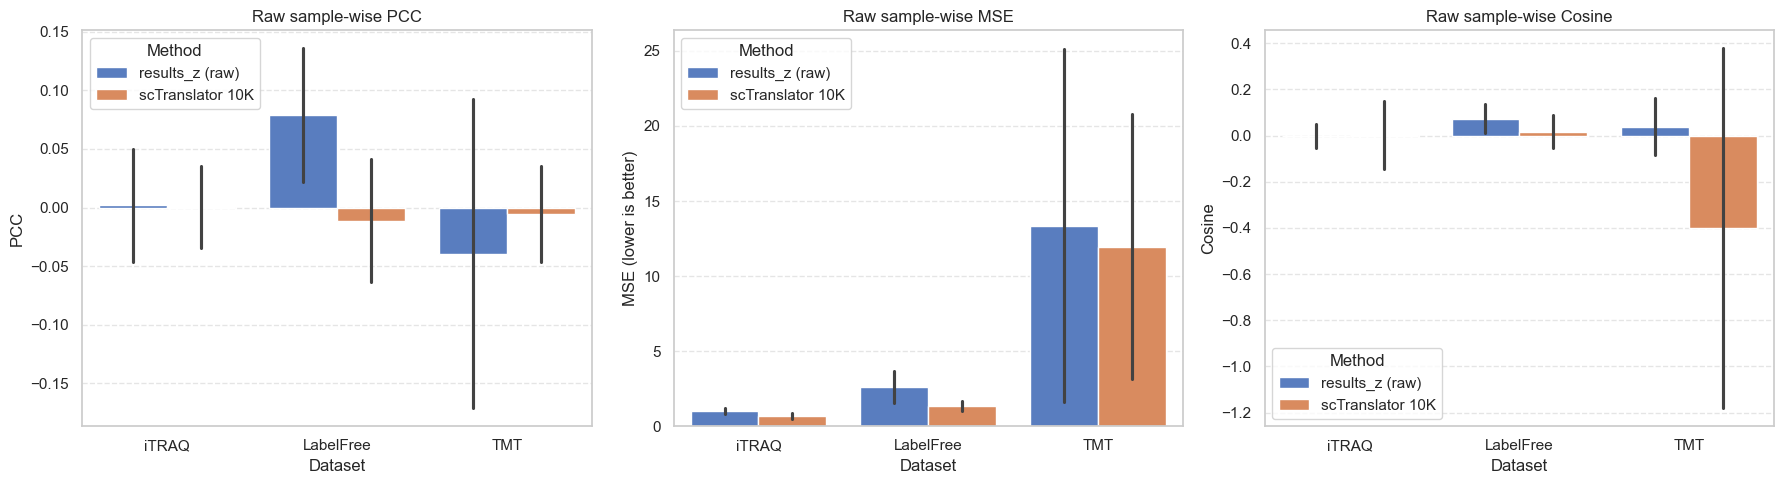

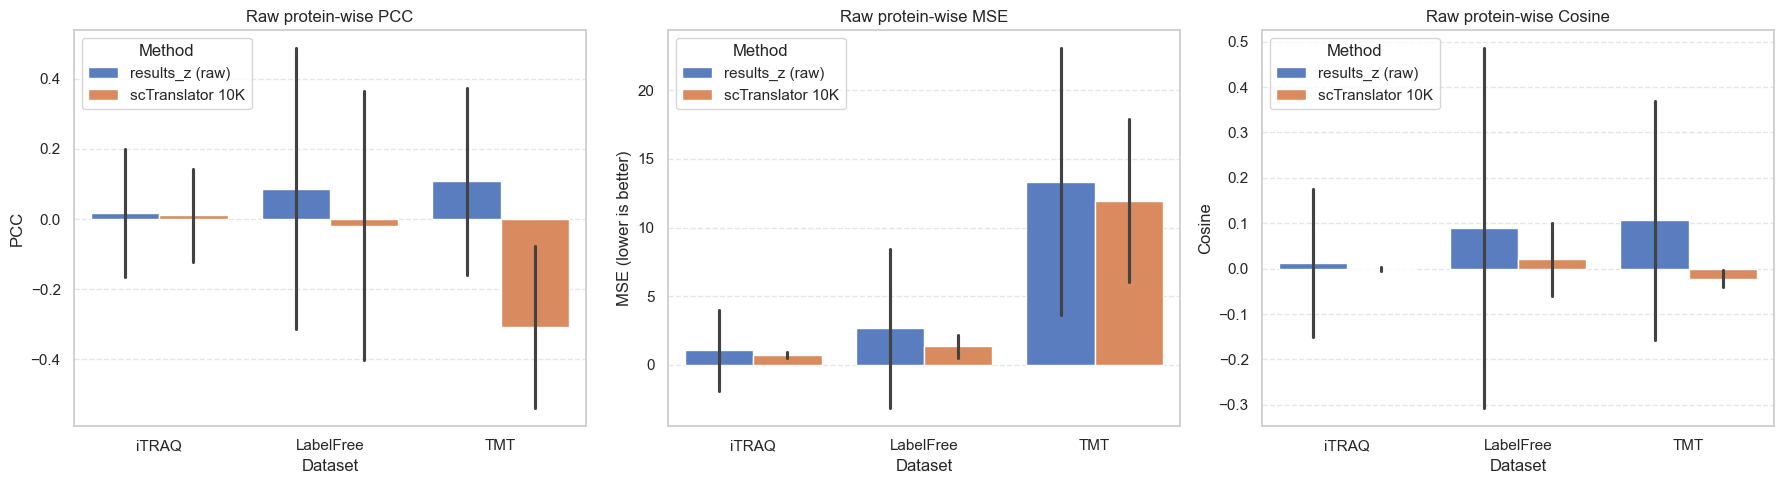

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['PCC', 'MSE', 'Cosine']):
    sns.barplot(
        data=raw_sample_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        ax=ax,
        errorbar='sd'
    )
    ax.set_title(f'Raw sample-wise {metric}')
    if metric == 'MSE':
        ax.set_ylabel('MSE (lower is better)')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'part1_raw_samplewise_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['PCC', 'MSE', 'Cosine']):
    sns.barplot(
        data=raw_protein_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        ax=ax,
        errorbar='sd'
    )
    ax.set_title(f'Raw protein-wise {metric}')
    if metric == 'MSE':
        ax.set_ylabel('MSE (lower is better)')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'part1_raw_proteinwise_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

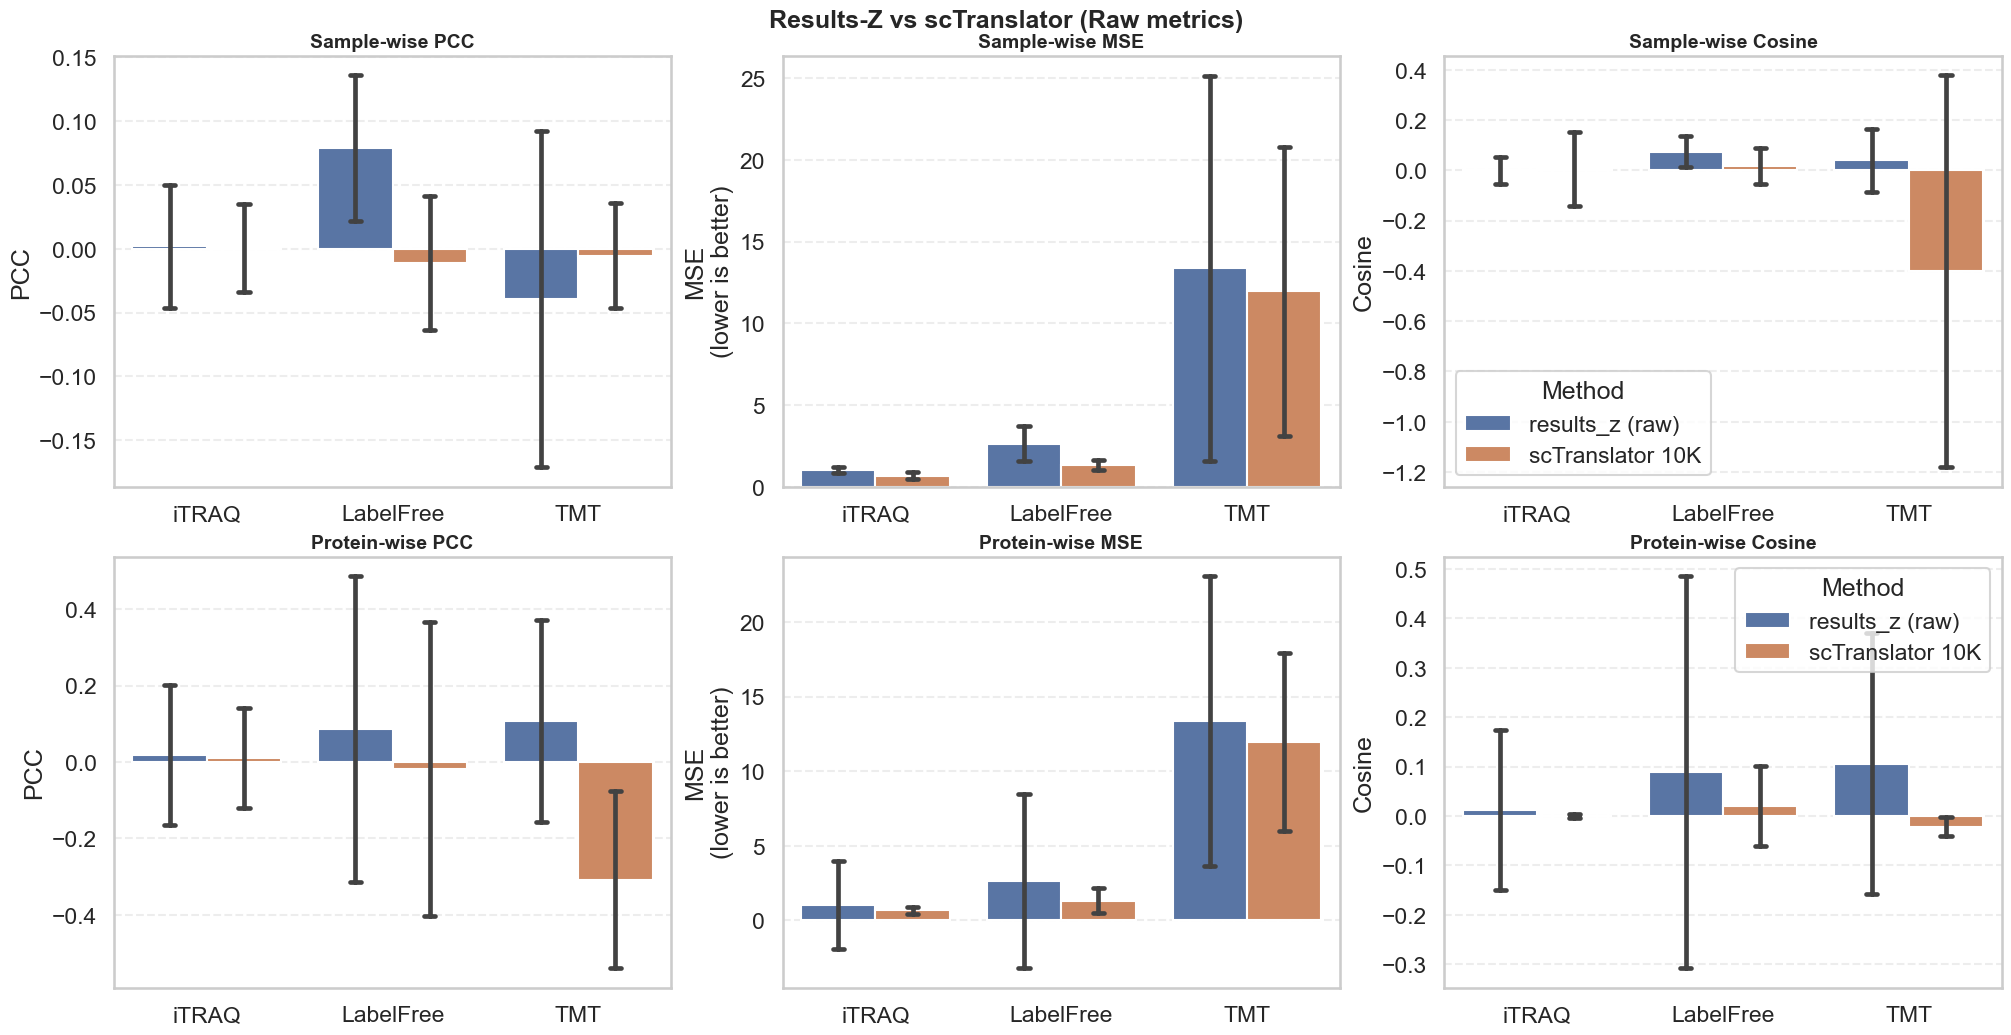

In [22]:
sns.set_theme(style='whitegrid', context='talk')

metrics_to_plot = ['PCC', 'MSE', 'Cosine']

fig, axes = plt.subplots(2, 3, figsize=(20, 10), constrained_layout=True)

for col, metric in enumerate(metrics_to_plot):
    ax = axes[0, col]
    sns.barplot(
        data=raw_sample_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        errorbar='sd',
        capsize=0.12,
        ax=ax
    )
    ax.set_title(f'Sample-wise {metric}', fontsize=14, weight='bold')
    ax.set_xlabel('')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    if metric == 'MSE':
        ax.set_ylabel('MSE\n(lower is better)')
    else:
        ax.set_ylabel(metric)

    if col == 2:
        ax.legend(title='Method', frameon=True)
    else:
        ax.get_legend().remove()

for col, metric in enumerate(metrics_to_plot):
    ax = axes[1, col]
    sns.barplot(
        data=raw_protein_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        errorbar='sd',
        capsize=0.12,
        ax=ax
    )
    ax.set_title(f'Protein-wise {metric}', fontsize=14, weight='bold')
    ax.set_xlabel('')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    if metric == 'MSE':
        ax.set_ylabel('MSE\n(lower is better)')
    else:
        ax.set_ylabel(metric)

    if col == 2:
        ax.legend(title='Method', frameon=True)
    else:
        ax.get_legend().remove()

fig.suptitle('Results-Z vs scTranslator (Raw metrics)', fontsize=18, weight='bold', y=1.02)

plt.savefig(OUTPUT_DIR / 'part1_raw_metrics_pretty.png', dpi=180, bbox_inches='tight')
plt.show()

## Part 2 — min-max normalization of the `results_z` truth / predictions

This applies your requested **scTranslator-style normalization** to the long comparison table, grouped **per sample** and **within each dataset** across the shared proteins:

```python
# normalize per sample, separately for true and predicted
comparison_df['true_mm'] = comparison_df.groupby(['Dataset', 'Sample'])['true_raw'].transform(normalization)
comparison_df['results_z_mm'] = comparison_df.groupby(['Dataset', 'Sample'])['results_z_raw'].transform(normalization)
```

The saved scTranslator 10K predictions are already on a min-max scale, so here they are only clipped to `[EPS, 1.0]` for safety.

In [17]:
comparison_df['true_mm'] = (
    comparison_df
    .groupby(['Dataset', 'Sample'], observed=True)['true_raw']
    .transform(normalization)
)
comparison_df['results_z_mm'] = (
    comparison_df
    .groupby(['Dataset', 'Sample'], observed=True)['results_z_raw']
    .transform(normalization)
)
comparison_df['sctranslator_10K_clip'] = comparison_df['sctranslator_10K'].clip(lower=EPS, upper=1.0)

comparison_df['true_mm'] = comparison_df['true_mm'].clip(lower=EPS, upper=1.0)
comparison_df['results_z_mm'] = comparison_df['results_z_mm'].clip(lower=EPS, upper=1.0)

comparison_df.to_csv(OUTPUT_DIR / 'comparison_long_with_minmax.csv', index=False)
display(comparison_df.head())

,Dataset,Sample,Protein,true_raw,results_z_raw,sctranslator_10K,true_mm,results_z_mm,sctranslator_10K_clip
0,iTRAQ,BREAST_2016_1,A2M,-0.031166,-3.955549,0.480229,0.443480,0.210864,0.480229
1,iTRAQ,BREAST_2016_1,AARS2,-0.242070,-0.187582,0.431823,0.373137,0.449102,0.431823
2,iTRAQ,BREAST_2016_1,AASDHPPT,0.316852,0.051874,0.569843,0.559556,0.464242,0.569843
3,iTRAQ,BREAST_2016_1,ABCB7,0.516458,0.200614,0.562814,0.626131,0.473646,0.562814
4,iTRAQ,BREAST_2016_1,ABCD3,-0.994526,-0.287270,0.594196,0.122168,0.442799,0.594196


In [18]:
norm_metric_specs = {
    'results_z_mm': 'results_z (min-max)',
    'sctranslator_10K_clip': 'scTranslator 10K',
}

norm_sample_metrics = []
norm_protein_metrics = []

for pred_col, method_name in norm_metric_specs.items():
    df_use = comparison_df[['Dataset', 'Sample', 'Protein', 'true_mm', pred_col]].copy()
    df_use = df_use.rename(columns={pred_col: 'pred'})

    sm = compute_group_metrics(df_use, true_col='true_mm', pred_col='pred', group_cols=['Dataset', 'Sample'])
    sm.insert(1, 'Method', method_name)
    norm_sample_metrics.append(sm)

    pm = compute_group_metrics(df_use, true_col='true_mm', pred_col='pred', group_cols=['Dataset', 'Protein'])
    pm.insert(1, 'Method', method_name)
    norm_protein_metrics.append(pm)

norm_sample_metrics = pd.concat(norm_sample_metrics, ignore_index=True)
norm_protein_metrics = pd.concat(norm_protein_metrics, ignore_index=True)

norm_sample_summary = summarize_metrics(norm_sample_metrics)
norm_protein_summary = summarize_metrics(norm_protein_metrics)

print('Sample-wise normalized summary')
display(norm_sample_summary)
print('Protein-wise normalized summary')
display(norm_protein_summary)

norm_sample_metrics.to_csv(OUTPUT_DIR / 'normalized_sample_metrics.csv', index=False)
norm_protein_metrics.to_csv(OUTPUT_DIR / 'normalized_protein_metrics.csv', index=False)
norm_sample_summary.to_csv(OUTPUT_DIR / 'normalized_sample_summary.csv', index=False)
norm_protein_summary.to_csv(OUTPUT_DIR / 'normalized_protein_summary.csv', index=False)

Sample-wise normalized summary


,Dataset,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,LabelFree,results_z (min-max),0.078714,0.073614,0.057133,0.090245,0.075971,0.071929,0.961867,0.962518,0.008944,0.037066,0.030398,0.019095,0.155038,0.140622,0.044442,-1.181216,-0.640436,1.285037,1807.0,1807.0,0.0
1,LabelFree,scTranslator 10K,-0.011174,-0.028194,0.052519,-0.009926,-0.027815,0.044026,0.959186,0.959413,0.008191,0.027599,0.026663,0.005181,0.131811,0.129738,0.012868,-0.603571,-0.524985,0.338392,1807.0,1807.0,0.0
2,TMT,results_z (min-max),-0.039351,-0.035184,0.131771,-0.063882,-0.043793,0.174409,0.955941,0.955247,0.011876,0.050637,0.043425,0.023728,0.183772,0.170453,0.049834,-1.722043,-1.226155,1.620760,1807.0,1807.0,0.0
3,TMT,scTranslator 10K,-0.005408,-0.013916,0.040914,-0.004499,-0.015957,0.044324,0.957711,0.960455,0.010983,0.030608,0.029575,0.007353,0.138781,0.135839,0.018075,-0.579631,-0.484607,0.355519,1807.0,1807.0,0.0
4,iTRAQ,results_z (min-max),0.002009,0.000829,0.048083,0.002298,0.000736,0.072211,0.961160,0.962388,0.012395,0.026328,0.023710,0.012405,0.128174,0.121883,0.030881,-0.707453,-0.401664,1.046754,1807.0,1807.0,0.0
5,iTRAQ,scTranslator 10K,0.000447,0.002399,0.034734,0.002037,0.003170,0.033032,0.956275,0.957461,0.012271,0.033307,0.031190,0.012415,0.146249,0.140797,0.030484,-1.176130,-0.815137,1.085491,1807.0,1807.0,0.0


Protein-wise normalized summary


,Dataset,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,LabelFree,results_z (min-max),0.082581,0.099582,0.310134,0.074156,0.087179,0.303627,0.942300,0.949825,0.031605,0.037066,0.031951,0.019816,0.155038,0.147399,0.041480,-1.414158,-0.958852,1.800194,360.0,360.0,0.0
1,LabelFree,scTranslator 10K,0.038719,0.012549,0.354883,0.028838,-0.004123,0.357045,0.966316,0.971502,0.022044,0.027599,0.022855,0.018754,0.131811,0.124469,0.042891,-0.599531,-0.328658,1.083031,360.0,360.0,0.0
2,TMT,results_z (min-max),-0.017594,-0.016903,0.096369,-0.027974,-0.023991,0.087646,0.923387,0.930240,0.031617,0.050637,0.047001,0.019669,0.183772,0.178299,0.034844,-1.621180,-1.363704,1.152164,1924.0,1924.0,0.0
3,TMT,scTranslator 10K,-0.002669,-0.002489,0.215788,-0.018770,-0.015940,0.201459,0.963602,0.969267,0.022270,0.030608,0.025858,0.018393,0.138781,0.131973,0.041112,-0.457422,-0.271347,0.595172,1924.0,1924.0,0.0
4,iTRAQ,results_z (min-max),-0.003570,-0.005586,0.122030,0.005876,0.007172,0.135091,0.951439,0.955810,0.021382,0.026328,0.023393,0.014627,0.128174,0.122731,0.030454,-0.259436,-0.140103,0.667625,276.0,276.0,0.0
5,iTRAQ,scTranslator 10K,0.034837,0.035557,0.117765,0.011661,0.010563,0.122624,0.958595,0.961598,0.014239,0.033307,0.029245,0.016932,0.146249,0.139188,0.037920,-0.633725,-0.330905,0.890194,276.0,276.0,0.0


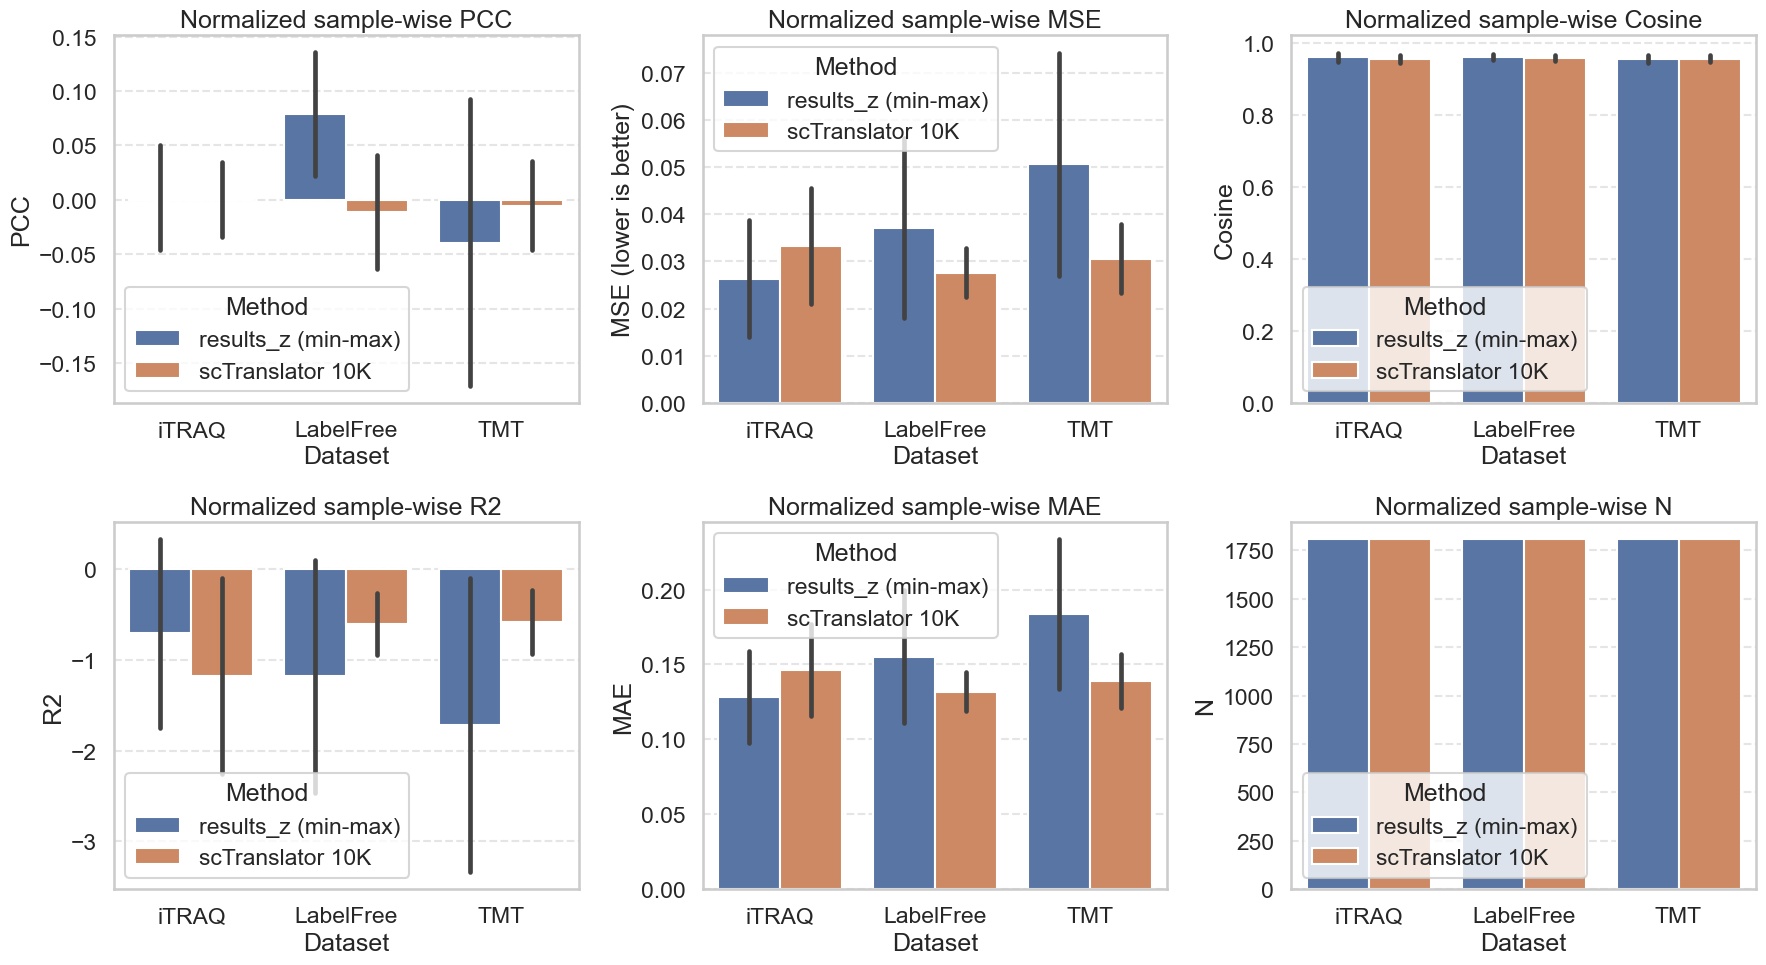

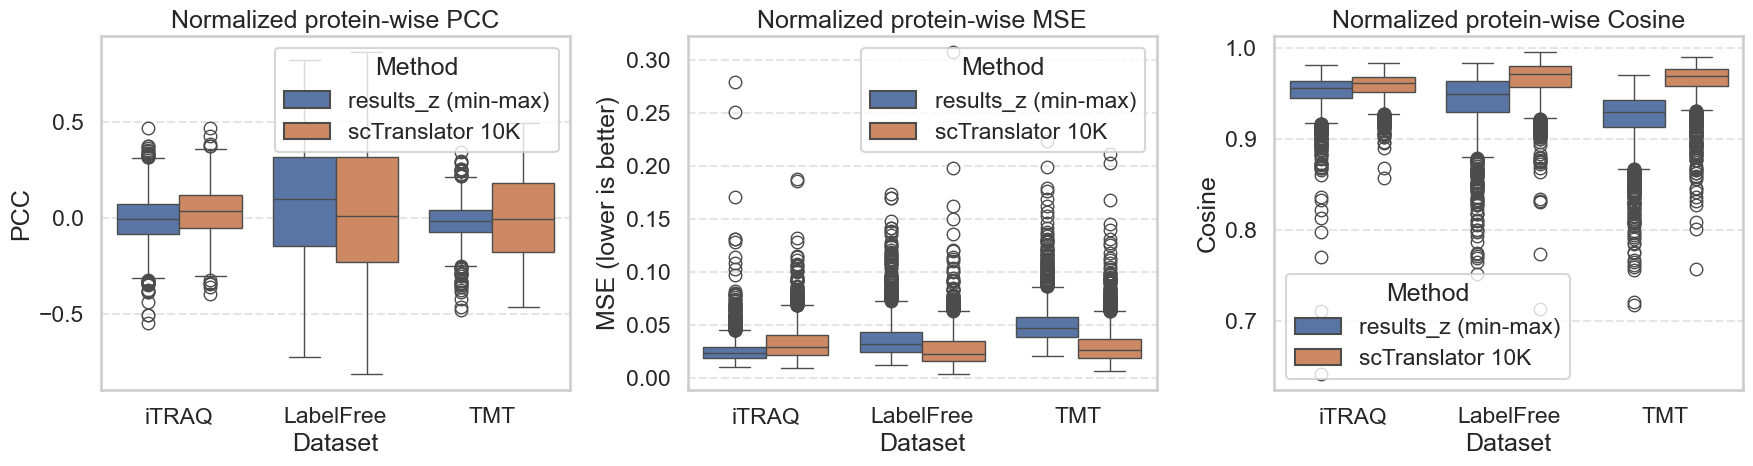

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
metrics = ['PCC', 'MSE', 'Cosine', 'R2', 'MAE', 'N']

for ax, metric in zip(axes.flat, metrics):
    sns.barplot(
        data=norm_sample_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        ax=ax,
        errorbar='sd'
    )
    ax.set_title(f'Normalized sample-wise {metric}')
    if metric == 'MSE':
        ax.set_ylabel('MSE (lower is better)')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'part2_normalized_samplewise_metrics_mse.png', dpi=150, bbox_inches='tight')
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['PCC', 'MSE', 'Cosine']):
    sns.boxplot(
        data=norm_protein_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        ax=ax
    )
    ax.set_title(f'Normalized protein-wise {metric}')
    if metric == 'MSE':
        ax.set_ylabel('MSE (lower is better)')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'part2_normalized_proteinwise_boxplots_mse.png', dpi=150, bbox_inches='tight')
plt.show()

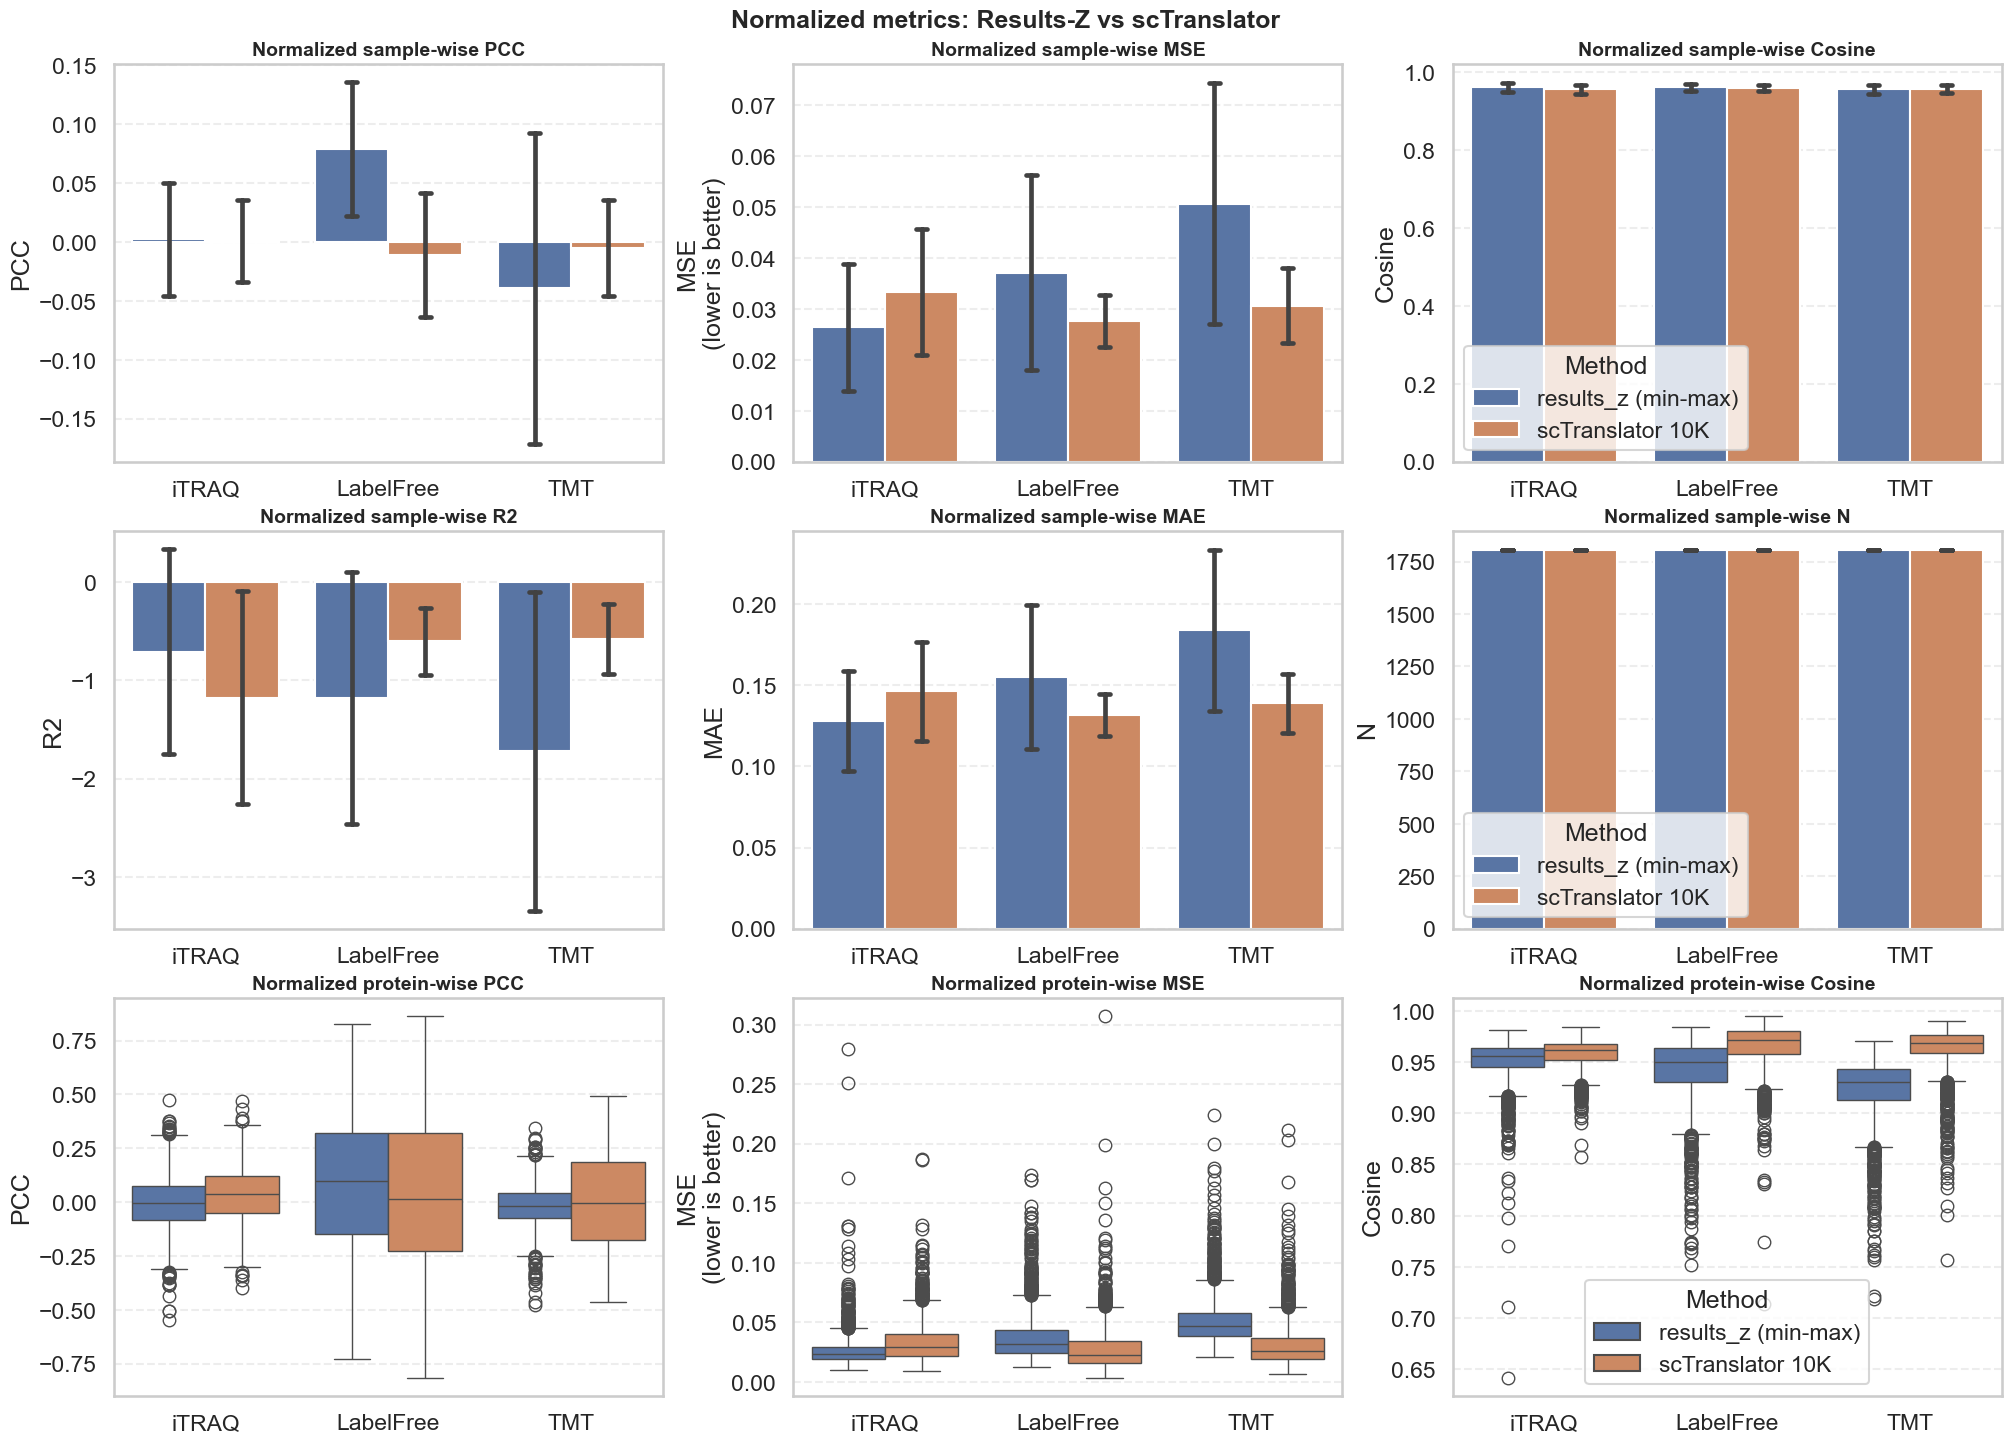

In [24]:
sns.set_theme(style='whitegrid', context='talk')

sample_metrics_to_plot = ['PCC', 'MSE', 'Cosine', 'R2', 'MAE', 'N']
protein_metrics_to_plot = ['PCC', 'MSE', 'Cosine']

fig, axes = plt.subplots(3, 3, figsize=(20, 14), constrained_layout=True)

# top 2 rows: normalized sample-wise barplots
for i, metric in enumerate(sample_metrics_to_plot):
    r, c = divmod(i, 3)
    ax = axes[r, c]

    sns.barplot(
        data=norm_sample_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        errorbar='sd',
        capsize=0.12,
        ax=ax
    )

    ax.set_title(f'Normalized sample-wise {metric}', fontsize=14, weight='bold')
    ax.set_xlabel('')
    ax.grid(axis='y', linestyle='--', alpha=0.35)

    if metric == 'MSE':
        ax.set_ylabel('MSE\n(lower is better)')
    else:
        ax.set_ylabel(metric)

    if c == 2:
        ax.legend(title='Method', frameon=True)
    else:
        ax.get_legend().remove()

# bottom row: normalized protein-wise boxplots
for c, metric in enumerate(protein_metrics_to_plot):
    ax = axes[2, c]

    sns.boxplot(
        data=norm_protein_metrics,
        x='Dataset',
        y=metric,
        hue='Method',
        ax=ax
    )

    ax.set_title(f'Normalized protein-wise {metric}', fontsize=14, weight='bold')
    ax.set_xlabel('')
    ax.grid(axis='y', linestyle='--', alpha=0.35)

    if metric == 'MSE':
        ax.set_ylabel('MSE\n(lower is better)')
    else:
        ax.set_ylabel(metric)

    if c == 2:
        ax.legend(title='Method', frameon=True)
    else:
        ax.get_legend().remove()

fig.suptitle('Normalized metrics: Results-Z vs scTranslator', fontsize=18, weight='bold', y=1.02)

plt.savefig(OUTPUT_DIR / 'part2_normalized_metrics_pretty_mse.png', dpi=180, bbox_inches='tight')
plt.show()

In [20]:
overall_norm_sample = summarize_metrics(norm_sample_metrics, by=('Method',))
overall_norm_protein = summarize_metrics(norm_protein_metrics, by=('Method',))

print('Overall normalized sample-wise summary')
display(overall_norm_sample)
print('Overall normalized protein-wise summary')
display(overall_norm_protein)

overall_norm_sample.to_csv(OUTPUT_DIR / 'overall_normalized_sample_summary.csv', index=False)
overall_norm_protein.to_csv(OUTPUT_DIR / 'overall_normalized_protein_summary.csv', index=False)

print(f'All tables and plots were saved to: {OUTPUT_DIR}')

Overall normalized sample-wise summary


,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,results_z (min-max),-0.018289,0.006984,0.124323,-0.035073,0.006849,0.164708,0.957337,0.957177,0.011817,0.046108,0.039556,0.023662,0.173737,0.162001,0.050937,-1.536603,-0.969200,1.562427,1807.0,1807.0,0.0
1,scTranslator 10K,-0.005588,-0.013325,0.042224,-0.004557,-0.014457,0.043293,0.957764,0.959944,0.010805,0.030476,0.029239,0.007937,0.138606,0.135302,0.019530,-0.647307,-0.498119,0.521098,1807.0,1807.0,0.0


Overall normalized protein-wise summary


,Method,PCC_mean,PCC_median,PCC_std,Spearman_mean,Spearman_median,Spearman_std,Cosine_mean,Cosine_median,Cosine_std,MSE_mean,MSE_median,MSE_std,MAE_mean,MAE_median,MAE_std,R2_mean,R2_median,R2_std,N_mean,N_median,N_std
0,results_z (min-max),0.020473,0.000855,0.205104,0.017352,-0.002305,0.202888,0.939042,0.946126,0.030899,0.038010,0.033351,0.020736,0.155661,0.150276,0.042455,-1.098258,-0.759384,1.424677,853.333333,360.0,757.921844
1,scTranslator 10K,0.023629,0.024116,0.249901,0.007243,0.002328,0.247789,0.962838,0.966614,0.020124,0.030505,0.026236,0.018190,0.138947,0.132468,0.041110,-0.563559,-0.299460,0.882470,853.333333,360.0,757.921844


All tables and plots were saved to: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\comparison_results_z_vs_scTranslator_10K


## Notes

- **Part 1** is the most faithful reconstruction of the original `results_z` output space, but it is not fully scale-matched to scTranslator 10K.
- **Part 2** is the fairer side-by-side comparison for scale-sensitive metrics because the `results_z` truth / predictions are transformed to the same style of per-sample min-max space.
- If you want, the notebook can be extended further to add paired statistical tests or per-dataset top-protein inspection tables.